`GOR 2026 Tutorial / An introduction to Time Series Machine Learning`

# Introduction to Time Series Machine Learning

This is the notebook associated with the introduction to the tutorial on time series
machine learning.

This tutorial builds on the ones we gave at KDD 2024 and ECML-PKDD 2024. The KDD tutorial
focussed on classification and regression, whereas this tutorial is an
introduction to a wider range of machine learning tasks.

All the material for this tutorial (notebooks and slides) is on [GitHub](https://github.com/aeon-toolkit/aeon-tutorials/tree/main/GOR-2026).
There are eight sections. Sections 1 to 7 each have a notebook (section 7 has two),
and section 8 has slides only. The sections are:

1. Introduction to Time Series Machine Learning
2. [Classification and regression](./part2_classification_regression.ipynb)
3. [Clustering](./part3_clustering.ipynb)
4. [Similarity Search](./part4_similarity_search.ipynb)
5. [Segmentation](./part5_segmentation.ipynb)
6. [Anomaly Detection](./part6_anomaly_detection.ipynb)
7. Deep Learning: [deep learning models in `aeon`](./part7_deep_learning_based.ipynb) and
   [a case study on rehabilitation exercise assessment](./part7_deep_learning_rehab_pile.ipynb)
8. Conclusions and future directions



In [ ]:
%pip install aeon==1.6.0 matplotlib seaborn

In [2]:
import os
import urllib.request

DATA_URL = "https://raw.githubusercontent.com/aeon-tutorials/KDD-2024/main/Notebooks/data/"
FILES = [
    "KDD_MTSC_TRAIN.ts",
    "KDD_MTSC_TEST.ts",
    "KDD_UTSC_TRAIN.ts",
    "KDD_UTSC_TEST.ts",
    "KDD_MTSER_TRAIN.ts",
    "KDD_MTSER_TEST.ts",
    "KDD_UTSER_TRAIN.ts",
    "KDD_UTSER_TEST.ts",
]
os.makedirs("data", exist_ok=True)
for f in FILES:
    if not os.path.exists(f"data/{f}"):
        urllib.request.urlretrieve(DATA_URL + f, f"data/{f}")

In [3]:
# Some dependencies raise warnings that do not affect the results; we hide them to keep the outputs readable.
import warnings

warnings.filterwarnings("ignore")

## `aeon` toolkit

The tutorial uses the `aeon` toolkit for machine learning from time series data. `aeon` is a `scikit-learn` compatible toolkit for time series machine learning (TSML). It is organised into
modules for different learning tasks: classification, regression, clustering, forecasting, anomaly detection, segmentation and similarity search. It also has building block modules for distances, networks and transformations.

Time for questions will be available after the tutorial itself. At any point if you have questions, please feel free to join our [Discord](https://discord.gg/D6rzqHGKRJ) and ask (a link is available here and on the `aeon` README).

In the following we load and showcase our example EEG datasets. All the datatypes used are 3D numpy arrays.

## Data structures and data sets

`aeon` assumes a single time series is a 2D numpy array of shape `(n_channels,
n_timepoints)`. Segmenters and most anomaly detectors work with single series; similarity search
looks for matches to a query within a collection. We refer to multiple series as a collection.  If the series
are all equal length, collections are best stored in a 3D numpy shape `(n_cases,
n_channels, n_timepoints)`. Unequal length series are stored in lists of 2D numpy, but the examples we are going to use will be equal length.

In [4]:
import numpy as np
single = np.random.random((3, 100)) # single three channel series, length 100
collection = np.random.random((10, 3, 100)) # 10 series of three channels, length 100

This tutorial will use an EEG dataset as a working example for collection estimators
(part 2 also uses the GunPoint dataset, and the deep learning part uses its own datasets).
We formatted this data for the KDD tutorial. The classification dataset is made of EEG
readings taken from a subject when at rest or when performing a set task (raising arms). Full info on this data can be found in the `aeon-neuro` [notebook](https://github.com/aeon-toolkit/aeon-neuro/blob/main/examples/data_loading.ipynb). Please do not over interpret any results from this data, it is a simple toy problem to demonstrate functionality.

`aeon` ships with some standard UCR and UEA datasets, and can download them all directly from [timeseriesclassification.com](https://timeseriesclassification.com) and the [tsml Zenodo community](https://zenodo.org/communities/tsml).

In [5]:
from aeon.datasets import load_from_ts_file

# Load the univariate EEG TSC dataset as a 3D numpy array
X_train_utsc, y_train_utsc = load_from_ts_file("./data/KDD_UTSC_TRAIN.ts")
X_test_utsc, y_test_utsc = load_from_ts_file("./data/KDD_UTSC_TEST.ts")

print("Single channel EEG TSC problem train shape:", X_train_utsc.shape)
print("Single channel EEG TSC problem test shape:", X_test_utsc.shape)

Single channel EEG TSC problem train shape: (40, 1, 100)
Single channel EEG TSC problem test shape: (40, 1, 100)


In [6]:
# Load the multivariate EEG TSC dataset as a 3D numpy array
X_train_mtsc, y_train_mtsc = load_from_ts_file("./data/KDD_MTSC_TRAIN.ts")
X_test_mtsc, y_test_mtsc = load_from_ts_file("./data/KDD_MTSC_TEST.ts")

print("Four channel EEG TSC problem train shape:", X_train_mtsc.shape)
print("Four channel EEG TSC problem test shape:", X_test_mtsc.shape)

Four channel EEG TSC problem train shape: (40, 4, 100)
Four channel EEG TSC problem test shape: (40, 4, 100)


In [7]:
# Load the univariate EEG TSER dataset as a 3D numpy array
X_train_utser, y_train_utser = load_from_ts_file("./data/KDD_UTSER_TRAIN.ts")
X_test_utser, y_test_utser = load_from_ts_file("./data/KDD_UTSER_TEST.ts")

print("Single channel EEG TSER problem train shape:", X_train_utser.shape)
print("Single channel EEG TSER problem test shape:", X_test_utser.shape)

Single channel EEG TSER problem train shape: (72, 1, 100)
Single channel EEG TSER problem test shape: (72, 1, 100)


In [8]:
# Load the multivariate EEG TSER dataset as a 3D numpy array
X_train_mtser, y_train_mtser = load_from_ts_file("./data/KDD_MTSER_TRAIN.ts")
X_test_mtser, y_test_mtser = load_from_ts_file("./data/KDD_MTSER_TEST.ts")

print("Four channel EEG TSER problem train shape:", X_train_mtser.shape)
print("Four channel EEG TSER problem test shape:", X_test_mtser.shape)

Four channel EEG TSER problem train shape: (72, 4, 100)
Four channel EEG TSER problem test shape: (72, 4, 100)


Here we plot each channel for the classification and regression data set. For classification we split each case by class value.

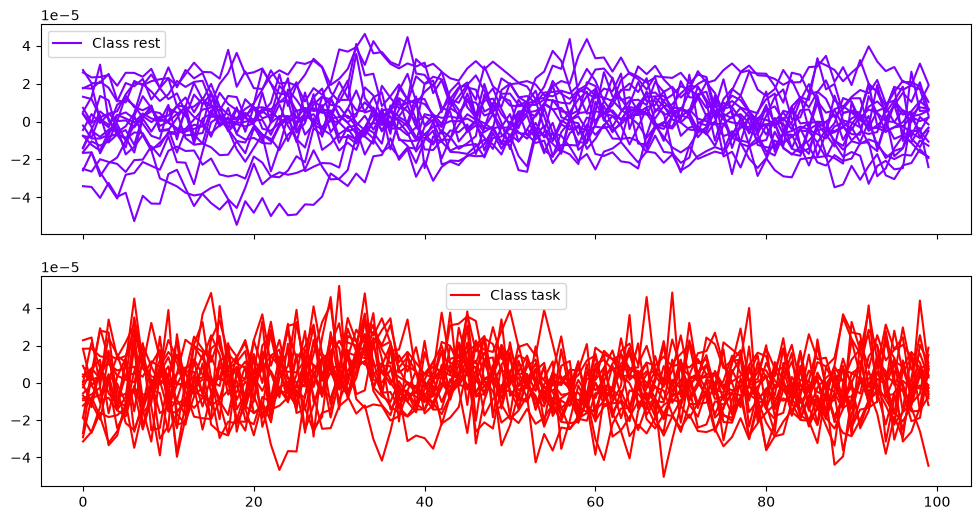

In [9]:
from aeon.visualisation import plot_collection_by_class

_ = plot_collection_by_class(X_train_mtsc[:, 0, :], y_train_utsc)

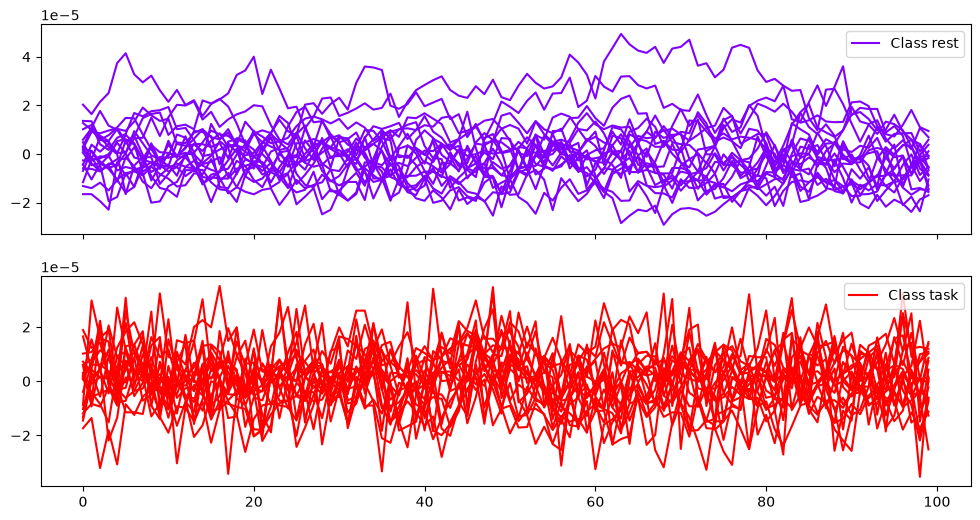

In [10]:
_ = plot_collection_by_class(X_train_mtsc[:, 1, :], y_train_utsc)

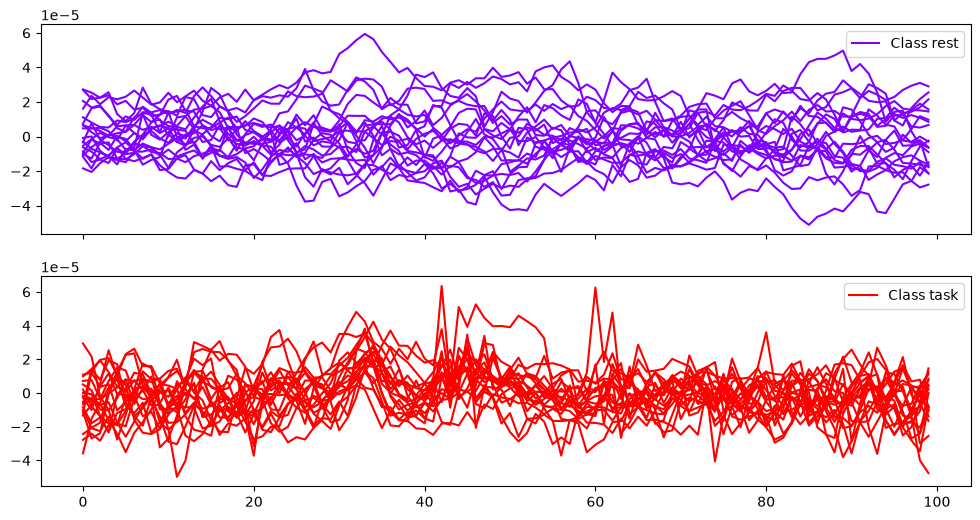

In [11]:
_ = plot_collection_by_class(X_train_mtsc[:, 2, :], y_train_utsc)

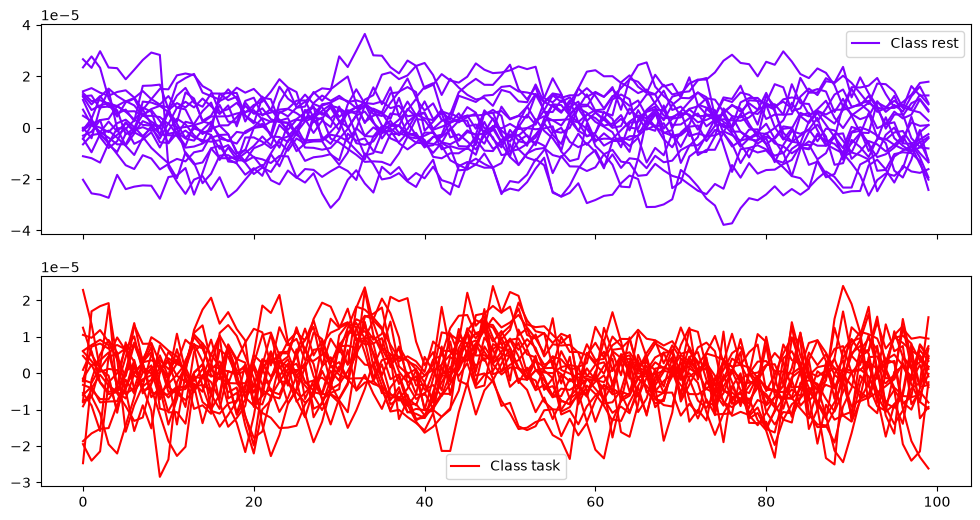

In [12]:
_ = plot_collection_by_class(X_train_mtsc[:, 3, :], y_train_utsc)

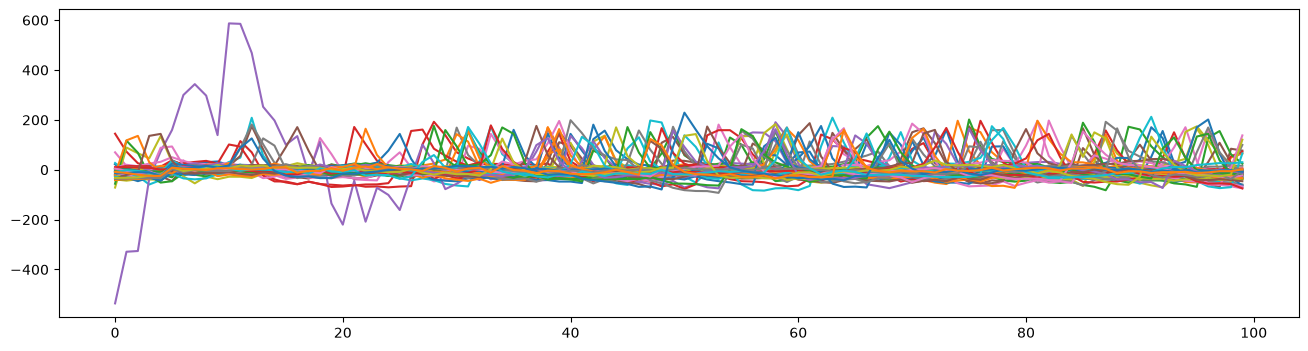

In [13]:
from aeon.visualisation import plot_series_collection

_ = plot_series_collection(X_test_mtser[:, 0, :])

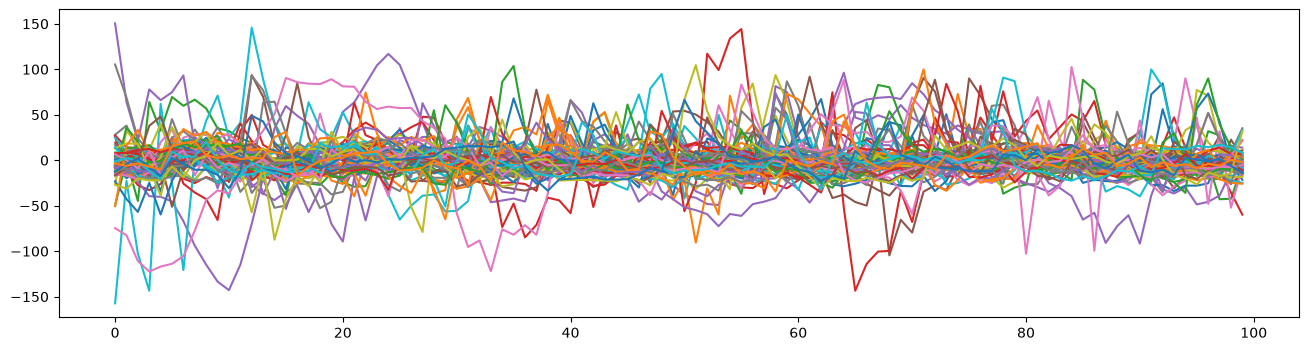

In [14]:
_ = plot_series_collection(X_test_mtser[:, 1, :])

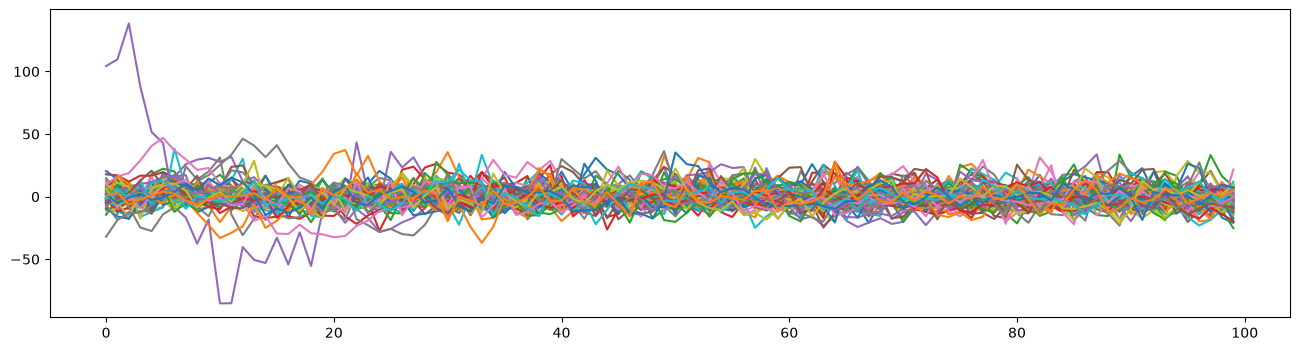

In [15]:
_ = plot_series_collection(X_test_mtser[:, 2, :])

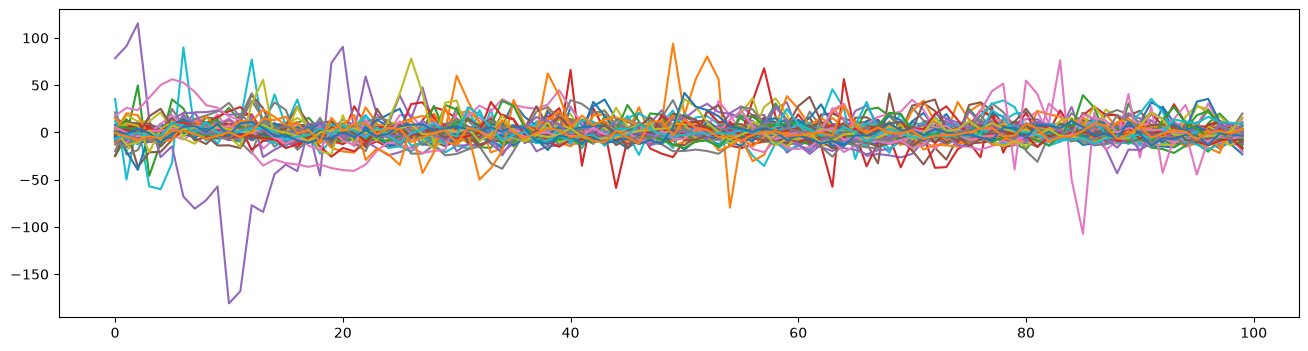

In [16]:
_ = plot_series_collection(X_test_mtser[:, 3, :])

## Basic collection estimator workflow

`aeon` follows the `scikit-learn` interface. Clusterers, classifiers and regressors
can be built using `fit`, and then prediction for new cases can be made using `predict`.

In [17]:
from aeon.classification.convolution_based import MiniRocketClassifier
from sklearn.metrics import accuracy_score

rc = MiniRocketClassifier(random_state=42)
rc.fit(X_train_utsc, y_train_utsc)
pred1 = rc.predict(X_test_utsc)
accuracy_score(y_test_utsc, pred1)

0.825

In [18]:
from aeon.regression.convolution_based import MiniRocketRegressor
from sklearn.metrics import mean_squared_error

rr = MiniRocketRegressor(random_state=42)
rr.fit(X_train_utser, y_train_utser)
pred2 = rr.predict(X_test_utser)
mean_squared_error(y_test_utser, pred2)

0.9274554494393494

In [19]:
from sklearn.metrics.cluster import adjusted_rand_score
from aeon.clustering import TimeSeriesKMeans
km = TimeSeriesKMeans(n_clusters=2, random_state=42)
km.fit(X_train_utsc)
pred3=km.predict(X_test_utsc)
adjusted_rand_score(y_test_utsc, pred3)

-0.0031576869942766925

## `sklearn` like classification, regression and clustering

`aeon` classifiers and regressors can be used in `scikit-learn` such as pipelines and
 tuning. Here is an example where we convert the data into its first 25 autocorrelation coefficients and construct a tuned MiniRocket classifier on this data.

In [20]:
from aeon.transformations.collection import AutocorrelationFunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV

pipe = make_pipeline(
    AutocorrelationFunctionTransformer(n_lags=25),
    MiniRocketClassifier(random_state=42),
)
param_grid = {'minirocketclassifier__n_kernels': [5000, 10000, 15000]}
grid = GridSearchCV(pipe, param_grid, cv=3)
grid.fit(X_train_utsc, y_train_utsc)
grid.best_params_

{'minirocketclassifier__n_kernels': 5000}

In [21]:
preds = grid.predict(X_test_utsc)
accuracy_score(y_test_utsc, preds)

0.5

# Similarity search

Similarity search involves finding close matches to a query series in a
collection of longer series. So, for example, we may look to the closest matches in
our EEG train data to a short segment of our test EEG data. Subsequence search
estimators, in `aeon.similarity_search.subsequence`, are given the query length
`length` when they are constructed. `fit` takes a collection
of time series as an argument of shape `(n_cases, n_channels, n_timepoints)`. `predict`
takes a query series, assumed to be shorter than the series in the collection, of
shape `(n_channels, length)`, where `length<n_timepoints`, and it returns the `k` closest
matches across the collection.

In [22]:
import numpy as np
from aeon.similarity_search.subsequence import NaiveSubsequenceSearch
q = np.array([[-2,-1,0,1,2,3]])
top_k_search = NaiveSubsequenceSearch(length=q.shape[1], distance="euclidean")
top_k_search.fit(X_train_utsc)
best_matches, distances = top_k_search.predict(q, k=3)
print(best_matches)

[[ 1 11]
 [ 5 10]
 [ 2 30]]


The similarity search estimators return two arrays. The first contains the location
of the `k` best matches, one row `(id_sample, id_timestamp)` per match. The
`id_sample` is the index of the series in the collection and the `id_timestamp` is
the start index of the match in the series. The second contains the distance of each
match to the query. By default, matches that start within half a query length of a better match in the
same series (trivial matches) are excluded; pass `allow_trivial_matches=True` to
`predict` to keep them. To query a single series, fit the estimator on a collection containing only
that series.

In [23]:
X = X_train_utsc[0:1]  # a collection containing only the first train series
q = X_test_utsc[0][:,0:10]
top_k_search = NaiveSubsequenceSearch(length=q.shape[1], distance="euclidean")
top_k_search.fit(X)
best_matches, distances = top_k_search.predict(q, k=3)
print(best_matches)

[[ 0 21]
 [ 0 10]
 [ 0 44]]


# Segmentation

Segmentation is a series task: a segmenter takes a single time series and splits it into
segments by finding change points.

In [24]:
from aeon.segmentation import ClaSPSegmenter, HidalgoSegmenter

clasp = ClaSPSegmenter( n_cps=2)
found_cps = clasp.fit_predict(X_train_utsc[0])
profiles = clasp.profiles
scores = clasp.scores
print("The found change points are", found_cps)


The found change points are [73 25]


# Deep learning

Spans all tasks, and as such has its own section in the tutorial.

## Further information

There is a lot of information available in the `aeon` documentation:

[`aeon` webpage](https://www.aeon-toolkit.org/en/stable/)

[Examples notebooks](https://www.aeon-toolkit.org/en/stable/examples.html)

You can get results published in clustering, classification and regression bake offs
 directly using `aeon`:

[Getting published results directly](https://www.aeon-toolkit.org/en/stable/examples/benchmarking/published_results.html)

More info on benchmarking:

[benchmarking](https://www.aeon-toolkit.org/en/stable/examples/benchmarking/benchmarking.html)

If you find anything wrong or unclear in the `aeon` documentation, please raise an issue on GitHub or mention it on Discord, we welcome new contributors.